For each of the
20000 ﬂights, you have access to the CO2 emissions, contrail impact expressed in a
CO2 equivalent metric (Global Warming Potential over 100 years) as well as other
parameters describing each ﬂight.

Your mission is to analyze the main drivers leading to contrail impact and propose
solutions to reduce it. These solutions can be both strategic or operational.

In [95]:
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import airportsdata
import pandas as pd

In [70]:
data = pd.read_csv("data_challenge.csv")

In [71]:
data.head()

,Aircraft,Engine,Role,Registration,Seats,Cargo Capacity (t),Flight Number,Date,Take-off Time (UTC),Origin Airport,Destination Airport,Distance OD (km),Distance Flown (km),CO2 (kgCO2e),Contrails (kgCO2e)
0,A20N,PW1127G-JM,PAX,EC-NFH,186.0,0.0,VY7835,2023-06-15,2023-06-15 16:01:00.000,EGKK,LEBL,1109.053917,1155.727519,11253.969499,0.000000
1,A20N,PW1127G-JM,PAX,EC-NIJ,186.0,0.0,VY7830,2023-06-15,2023-06-15 05:12:20.000000000,LEBL,EGKK,1109.053917,1255.367953,11965.946434,16370.295266
2,A20N,PW1127G-JM,PAX,EC-NCT,186.0,0.0,VY3212,2023-12-31,2023-12-31 10:52:17.000,LEBL,GCXO,2194.502853,NaN,19808.910939,NaN
3,A20N,PW1127G-JM,PAX,EC-NCF,186.0,0.0,VY6213,2023-10-09,2023-10-09 15:49:00.403000000,LEMG,LIRF,1548.024410,1590.238353,14352.387644,41217.801880
4,A321,CFM56-5B3/3,PAX,EC-NLY,220.0,0.0,VY8748,2023-11-02,2023-11-02 13:50:32.000000000,EGCC,LEBL,1379.156221,1492.741633,20147.168918,11686.423628


In [72]:
# Contrails can be negative, so we must take the absolute value of the contrails column
data['Contrails (kgCO2e)'] = data['Contrails (kgCO2e)'].abs()

### Some ideas to test
- Aircraft and engine types may have a direct impact on the amount of contrails produced
- Inter-continental vs intra-continental flights 
- Seasons

In [73]:
# Let's get rid of some columns that won't be useful to us
drop_cols = ['Role', 'Registration', 'Seats', 'Cargo Capacity (t)', 'Flight Number']
data.columns
data.drop(columns=drop_cols, inplace=True)
data.head()

C:\Users\johnn\AppData\Local\Temp\ipykernel_36188\773771547.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=drop_cols, inplace=True)


,Aircraft,Engine,Date,Take-off Time (UTC),Origin Airport,Destination Airport,Distance OD (km),Distance Flown (km),CO2 (kgCO2e),Contrails (kgCO2e)
0,A20N,PW1127G-JM,2023-06-15,2023-06-15 16:01:00.000,EGKK,LEBL,1109.053917,1155.727519,11253.969499,0.000000
1,A20N,PW1127G-JM,2023-06-15,2023-06-15 05:12:20.000000000,LEBL,EGKK,1109.053917,1255.367953,11965.946434,16370.295266
2,A20N,PW1127G-JM,2023-12-31,2023-12-31 10:52:17.000,LEBL,GCXO,2194.502853,NaN,19808.910939,NaN
3,A20N,PW1127G-JM,2023-10-09,2023-10-09 15:49:00.403000000,LEMG,LIRF,1548.024410,1590.238353,14352.387644,41217.801880
4,A321,CFM56-5B3/3,2023-11-02,2023-11-02 13:50:32.000000000,EGCC,LEBL,1379.156221,1492.741633,20147.168918,11686.423628


In [74]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Aircraft             20000 non-null  str    
 1   Engine               20000 non-null  str    
 2   Date                 20000 non-null  str    
 3   Take-off Time (UTC)  20000 non-null  str    
 4   Origin Airport       20000 non-null  str    
 5   Destination Airport  20000 non-null  str    
 6   Distance OD (km)     19999 non-null  float64
 7   Distance Flown (km)  19329 non-null  float64
 8   CO2 (kgCO2e)         19999 non-null  float64
 9   Contrails (kgCO2e)   19329 non-null  float64
dtypes: float64(4), str(6)
memory usage: 1.5 MB


In [75]:
# Convert appropriate columns into the appropriate dtypes
data['Take-off Time (UTC)'] = pd.to_datetime(data['Take-off Time (UTC)'])

# extract clock time
data['Take-off Time (UTC)'] = pd.to_datetime(data['Take-off Time (UTC)']).dt.strftime('%H:%M:%S')


In [76]:
data.head()

,Aircraft,Engine,Date,Take-off Time (UTC),Origin Airport,Destination Airport,Distance OD (km),Distance Flown (km),CO2 (kgCO2e),Contrails (kgCO2e)
0,A20N,PW1127G-JM,2023-06-15,16:01:00,EGKK,LEBL,1109.053917,1155.727519,11253.969499,0.000000
1,A20N,PW1127G-JM,2023-06-15,05:12:20,LEBL,EGKK,1109.053917,1255.367953,11965.946434,16370.295266
2,A20N,PW1127G-JM,2023-12-31,10:52:17,LEBL,GCXO,2194.502853,NaN,19808.910939,NaN
3,A20N,PW1127G-JM,2023-10-09,15:49:00,LEMG,LIRF,1548.024410,1590.238353,14352.387644,41217.801880
4,A321,CFM56-5B3/3,2023-11-02,13:50:32,EGCC,LEBL,1379.156221,1492.741633,20147.168918,11686.423628


In [77]:
# drop NaN columns too
data.dropna(axis=0, inplace=True)


C:\Users\johnn\AppData\Local\Temp\ipykernel_36188\2058975928.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(axis=0, inplace=True)


In [78]:
aircraft_types = data['Aircraft'].unique()
engine_types = data['Engine'].unique()
print(aircraft_types), print(engine_types)

<StringArray>
['A20N', 'A321', 'A320', 'A21N', 'A319']
Length: 5, dtype: str
<StringArray>
[ 'PW1127G-JM', 'CFM56-5B3/3',    'V2527-A5', 'CFM56-5B4/3',    'V2533-A5',
 'CFM56-5B6/P', 'CFM56-5B4/P', 'CFM56-5B6/3',  'PW1133G-JM']
Length: 9, dtype: str


(None, None)

In [79]:
data['Aircraft'].value_counts()

Aircraft
A320    11632
A20N     3408
A321     2997
A319      904
A21N      388
Name: count, dtype: int64

In [80]:
data['Engine'].value_counts()

Engine
V2527-A5       5574
CFM56-5B4/3    3538
PW1127G-JM     3408
V2533-A5       2435
CFM56-5B6/P    1630
CFM56-5B4/P    1289
CFM56-5B3/3     562
CFM56-5B6/3     505
PW1133G-JM      388
Name: count, dtype: int64

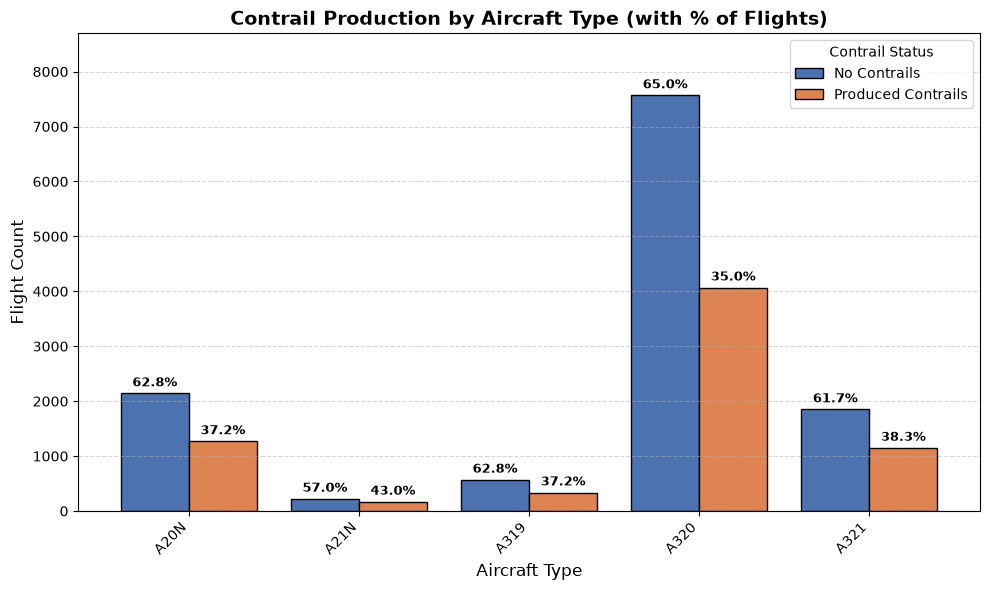

In [81]:
df = data
has_contrails = df['Contrails (kgCO2e)'] > 0
counts = pd.crosstab(
    df['Aircraft'], 
    has_contrails
).rename(columns={False: 'No Contrails', True: 'Produced Contrails'})

# 2. Calculate percentages per aircraft type (row-wise)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

# 3. Plot grouped bars
ax = counts.plot(
    kind='bar', 
    figsize=(10, 6), 
    width=0.8,
    color=['#4C72B0', '#DD8452'],
    edgecolor='black'
)

# 4. Attach percentage labels above each bar
for col_idx, container in enumerate(ax.containers):
    labels = [f"{percentages.iloc[row_idx, col_idx]:.1f}%" for row_idx in range(len(counts))]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, weight='bold')

# Expand y-limit slightly to give headroom for the labels
ax.set_ylim(0, counts.to_numpy().max() * 1.15)

plt.title('Contrail Production by Aircraft Type (with % of Flights)', fontsize=14, weight='bold')
plt.xlabel('Aircraft Type', fontsize=12)
plt.ylabel('Flight Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Contrail Status')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

Looking at this graph, we can see 35% to 43% of all flights produced contrails.

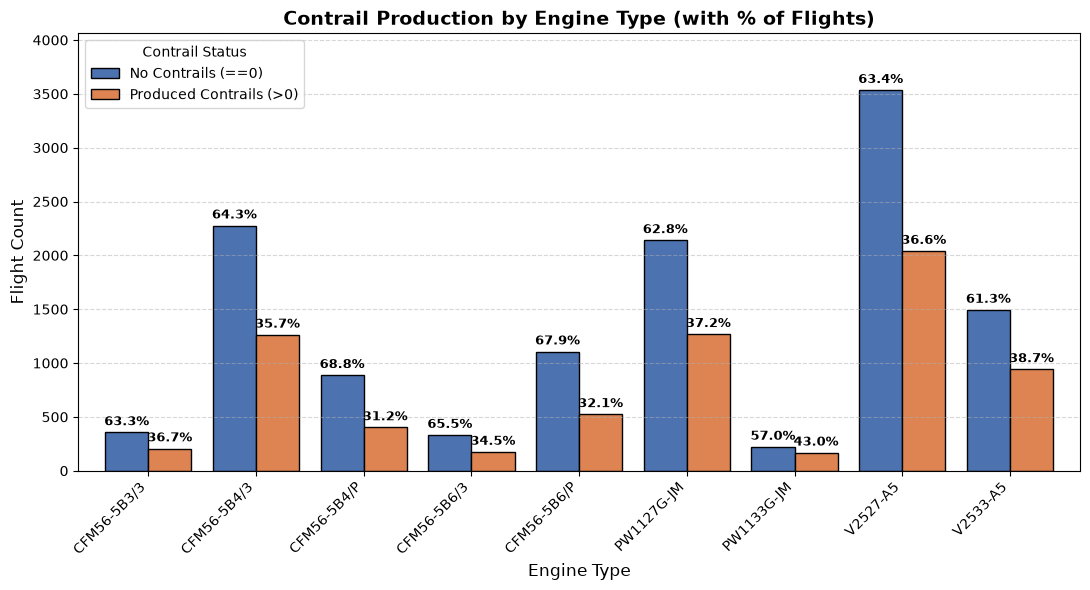

In [82]:
# 1. Categorize contrail occurrence
has_contrails = data['Contrails (kgCO2e)'] > 0

# 2. Cross-tabulate Engine vs Contrail status
counts = pd.crosstab(
    data['Engine'], 
    has_contrails
).rename(columns={False: 'No Contrails (==0)', True: 'Produced Contrails (>0)'})

# 3. Calculate percentage per engine model
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

# 4. Plot grouped bars
ax = counts.plot(
    kind='bar', 
    figsize=(11, 6), 
    width=0.8,
    color=['#4C72B0', '#DD8452'],
    edgecolor='black'
)

# 5. Add percentage labels above each bar
for col_idx, container in enumerate(ax.containers):
    labels = [f"{percentages.iloc[row_idx, col_idx]:.1f}%" for row_idx in range(len(counts))]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, weight='bold')

# Expand y-limit to prevent labels from getting clipped
ax.set_ylim(0, counts.to_numpy().max() * 1.15)

plt.title('Contrail Production by Engine Type (with % of Flights)', fontsize=14, weight='bold')
plt.xlabel('Engine Type', fontsize=12)
plt.ylabel('Flight Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Contrail Status')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

It's a similar story, the percentage of flights that produced contrails still sits in the 20% range approximately. 
My first thought is that there is something characteristic of the flights themselves, not the aircraft models, such as Origin-Destination.
Before we explore further though, let's look at a distribution of the absolute value of contrails produced per aircraft type.
Then we can look at engine types per aircraft.

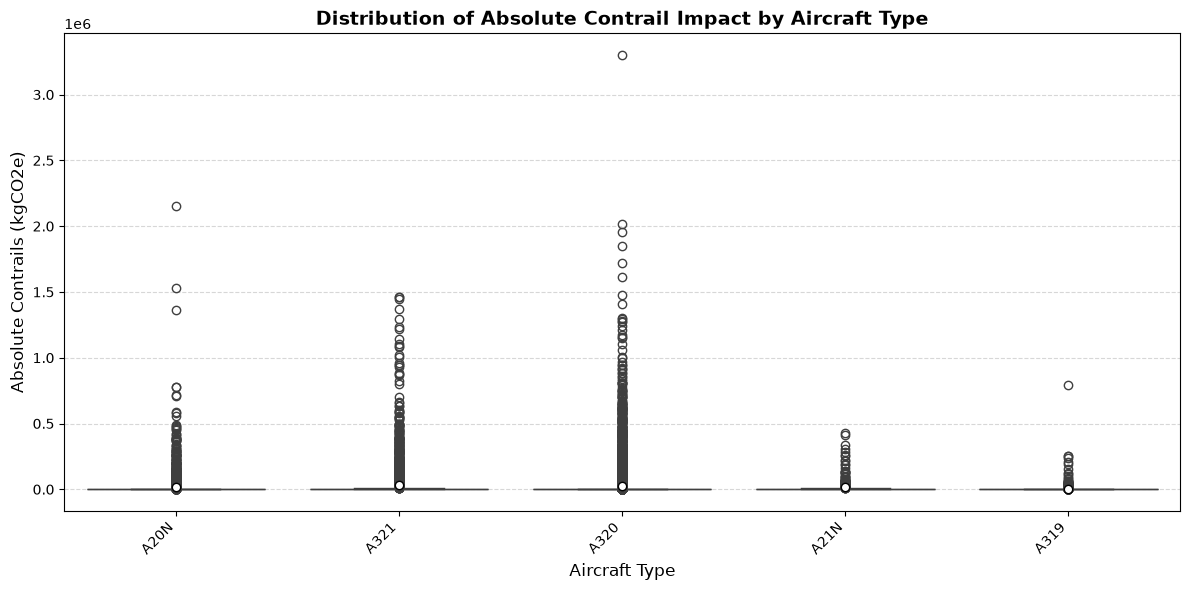

In [83]:
plt.figure(figsize=(12, 6))

# Create a box plot comparing aircraft distributions
sns.boxplot(
    data=data,
    x='Aircraft',
    y='Contrails (kgCO2e)',
    
    showmeans=True, # Optional: shows mean marker as well as median line
    meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black'}
)

plt.title('Distribution of Absolute Contrail Impact by Aircraft Type', fontsize=14, weight='bold')
plt.xlabel('Aircraft Type', fontsize=12)
plt.ylabel('Absolute Contrails (kgCO2e)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

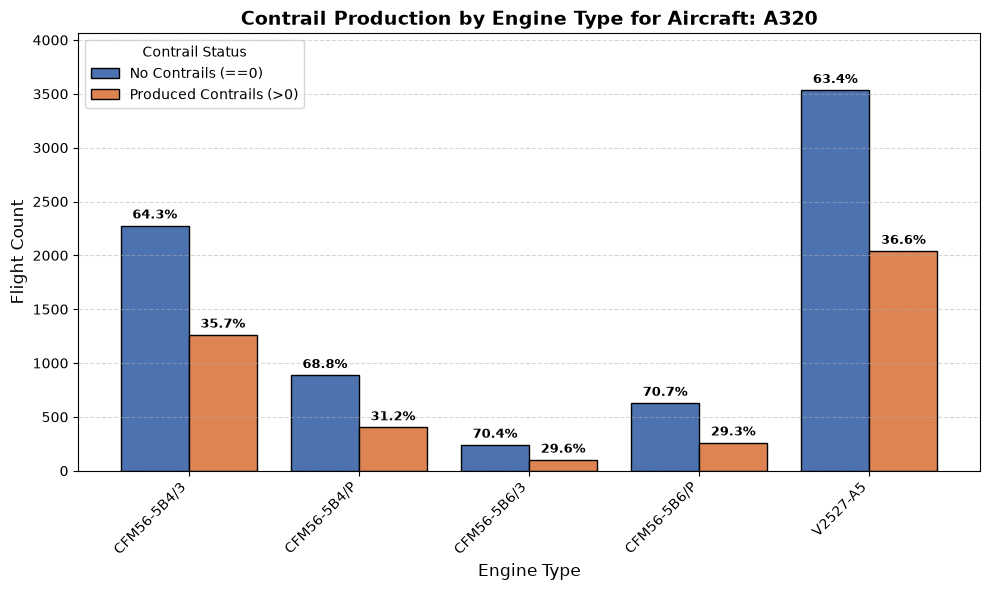

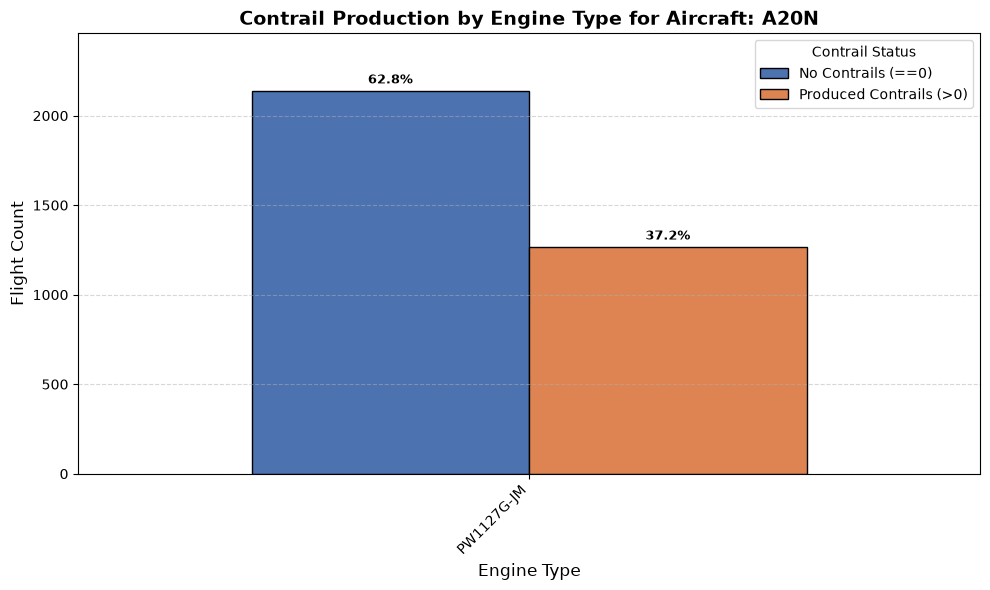

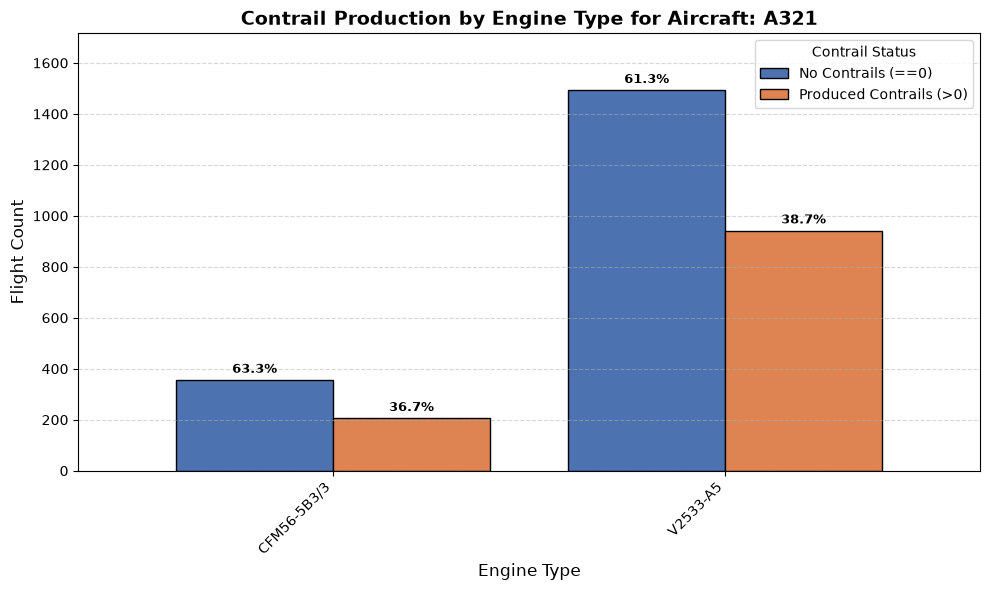

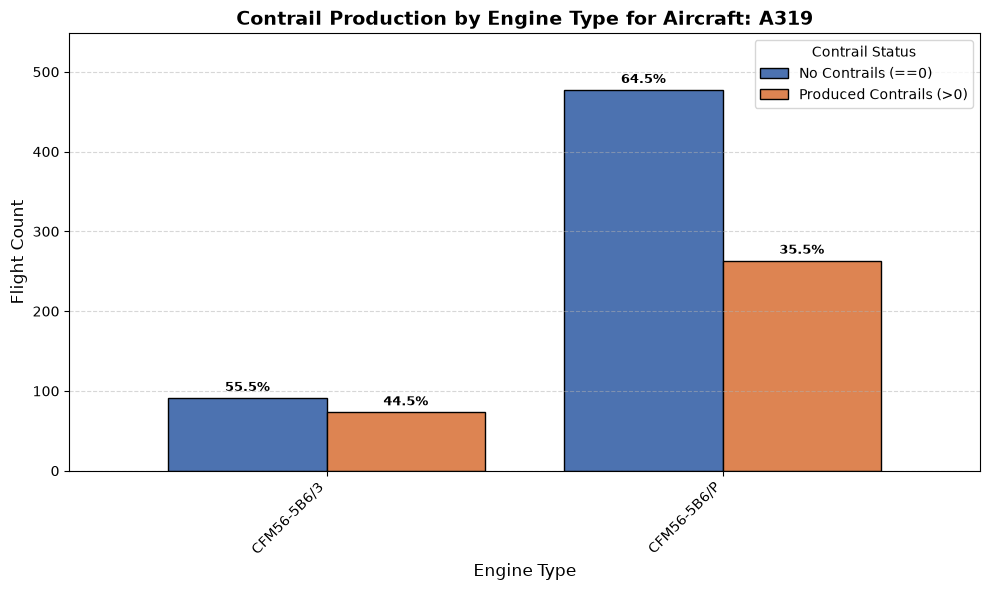

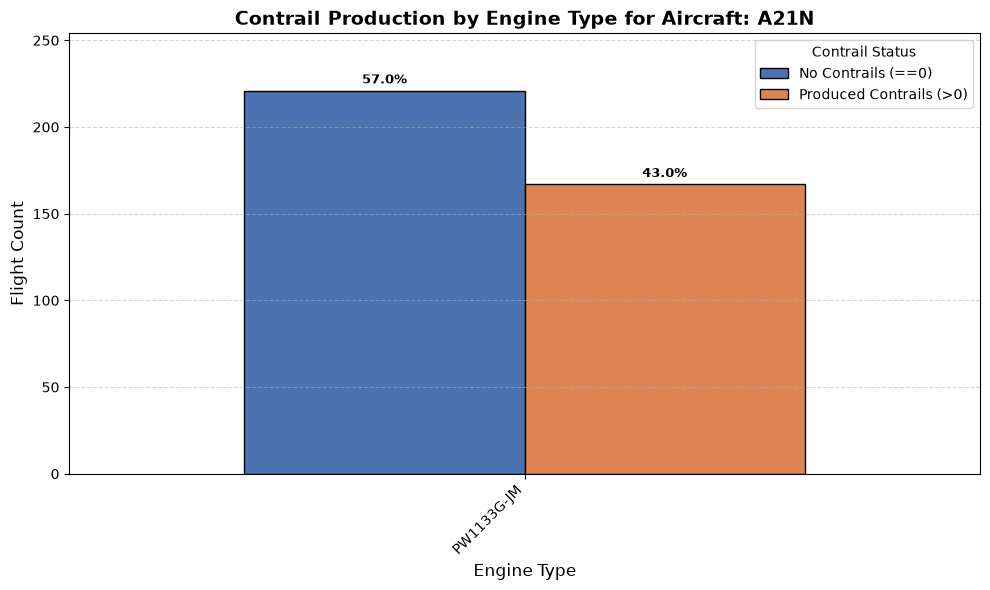

In [84]:
def plot_engine_contrails_by_aircraft(data, target_aircraft):
    """
    Plots a grouped bar chart showing contrail production by engine type
    for a specific aircraft model.
    
    Parameters:
    - data (pd.DataFrame): The main dataframe containing 'Aircraft', 'Engine', and 'Contrails (kgCO2e)'
    - target_aircraft (str): The specific aircraft model to filter by (e.g., 'A320')
    """
    # 1. Filter for the specific aircraft
    data_subset = data[data['Aircraft'] == target_aircraft].copy()
    
    if data_subset.empty:
        print(f"⚠️ Warning: No records found for aircraft type '{target_aircraft}'.")
        return

    # 2. Categorize contrail occurrence (> 0 vs == 0)
    has_contrails = data_subset['Contrails (kgCO2e)'] > 0

    # 3. Cross-tabulate Engine vs Contrail status
    counts = pd.crosstab(
        data_subset['Engine'], 
        has_contrails
    ).rename(columns={False: 'No Contrails (==0)', True: 'Produced Contrails (>0)'})

    if counts.empty:
        print(f"⚠️ Warning: No engine data available for '{target_aircraft}'.")
        return

    # 4. Calculate row-wise percentages per engine type
    percentages = counts.div(counts.sum(axis=1), axis=0).fillna(0) * 100

    # 5. Plot grouped bars
    fig, ax = plt.subplots(figsize=(10, 6))
    counts.plot(
        kind='bar', 
        ax=ax,
        width=0.8,
        color=['#4C72B0', '#DD8452'],
        edgecolor='black'
    )

    # 6. Add percentage labels above each bar
    for col_idx, container in enumerate(ax.containers):
        labels = [f"{percentages.iloc[row_idx, col_idx]:.1f}%" for row_idx in range(len(counts))]
        ax.bar_label(container, labels=labels, padding=3, fontsize=9, weight='bold')

    # Give headroom for labels
    max_val = counts.to_numpy().max() if counts.size > 0 else 1
    ax.set_ylim(0, max_val * 1.15)

    # Styling
    plt.title(f'Contrail Production by Engine Type for Aircraft: {target_aircraft}', fontsize=14, weight='bold')
    plt.xlabel('Engine Type', fontsize=12)
    plt.ylabel('Flight Count', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Contrail Status')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()

    plt.show()
plot_engine_contrails_by_aircraft(data, 'A320')
plot_engine_contrails_by_aircraft(data, 'A20N')
plot_engine_contrails_by_aircraft(data, 'A321')
plot_engine_contrails_by_aircraft(data, 'A319')
plot_engine_contrails_by_aircraft(data, 'A21N')

Contrails typically form at high cruising altitudes. High atmospheric humidity also encourages contrail formation.

Does nighttime flying affect contrail formation?

Winter months in the north hemisphere?

Winter months in the south hemisphere?

Create indicator features for origin airport season? Long-haul flight? 

Let's explore long-haul flights first.
The UK CAA defines long-haul as greawter than 3000 km. Eurocontrol defines it as greater than 4000 km and the European Union says 3500km.
Let's try 3500 for now, and we can change it to see what happens to our analysis.


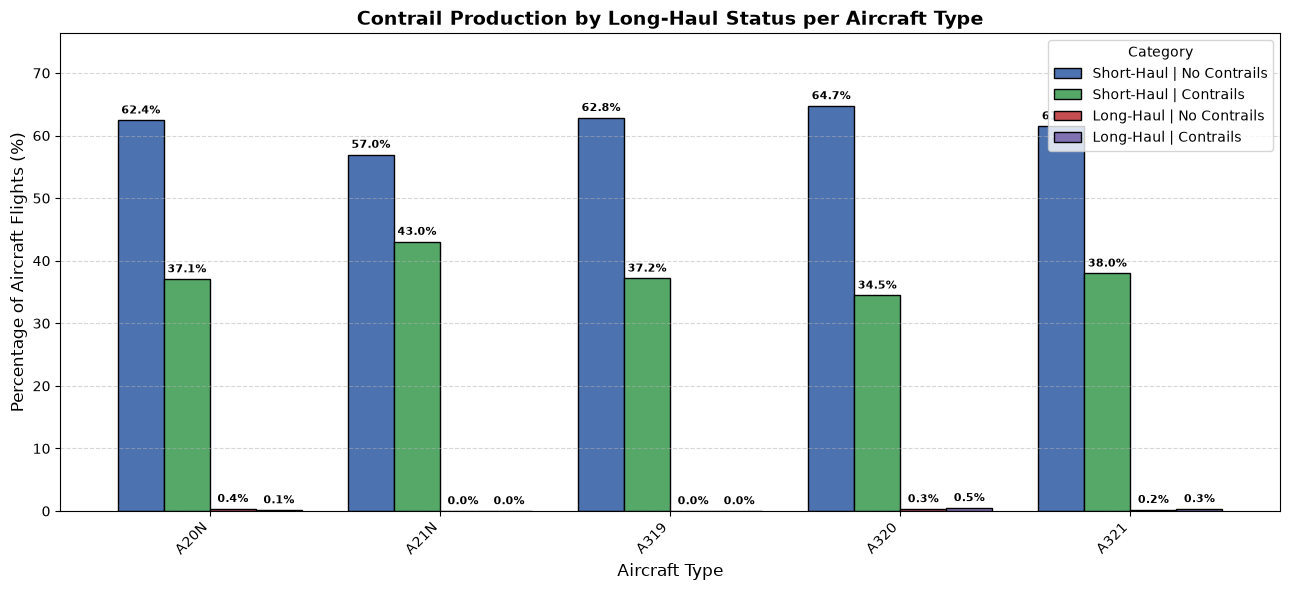

In [89]:
# Let's look at the OD distance to see if it is a long-haul flight.
lh_threshold = 3000  # long-haul threshold in OD km


# Ensure long-haul is a boolean condition (handles 1/0 or True/False)
is_long_haul = data['Distance OD (km)'] > lh_threshold
has_contrails = data['Contrails (kgCO2e)'] > 0

# 2. Assign the 4 mutually exclusive categories
conditions = [
    (~is_long_haul) & (~has_contrails),
    (~is_long_haul) & (has_contrails),
    (is_long_haul) & (~has_contrails),
    (is_long_haul) & (has_contrails)
]

labels = [
    'Short-Haul | No Contrails',
    'Short-Haul | Contrails',
    'Long-Haul | No Contrails',
    'Long-Haul | Contrails'
]

data['Category'] = np.select(conditions, labels, default='Other')

# 3. Calculate row-wise percentages (% of each aircraft's total flights)
pct_table = pd.crosstab(
    data['Aircraft'], 
    data['Category'], 
    normalize='index'
) * 100

# Reorder columns logically
pct_table = pct_table[[c for c in labels if c in pct_table.columns]]

# 4. Plot 4 grouped bars per aircraft
fig, ax = plt.subplots(figsize=(13, 6))

pct_table.plot(
    kind='bar',
    ax=ax,
    width=0.8,
    color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'],
    edgecolor='black'
)

# 5. Add percentage labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=8, weight='bold')

# Expand y-limit to provide headroom for annotations
ax.set_ylim(0, pct_table.to_numpy().max() * 1.18)

plt.title('Contrail Production by Long-Haul Status per Aircraft Type', fontsize=14, weight='bold')
plt.xlabel('Aircraft Type', fontsize=12)
plt.ylabel('Percentage of Aircraft Flights (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Category', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

Barely any of the flights were long-haul. There is a slight error here though. The percentages are indicated as a fraction of the total flights with that aircraft type, so it can be misleading.

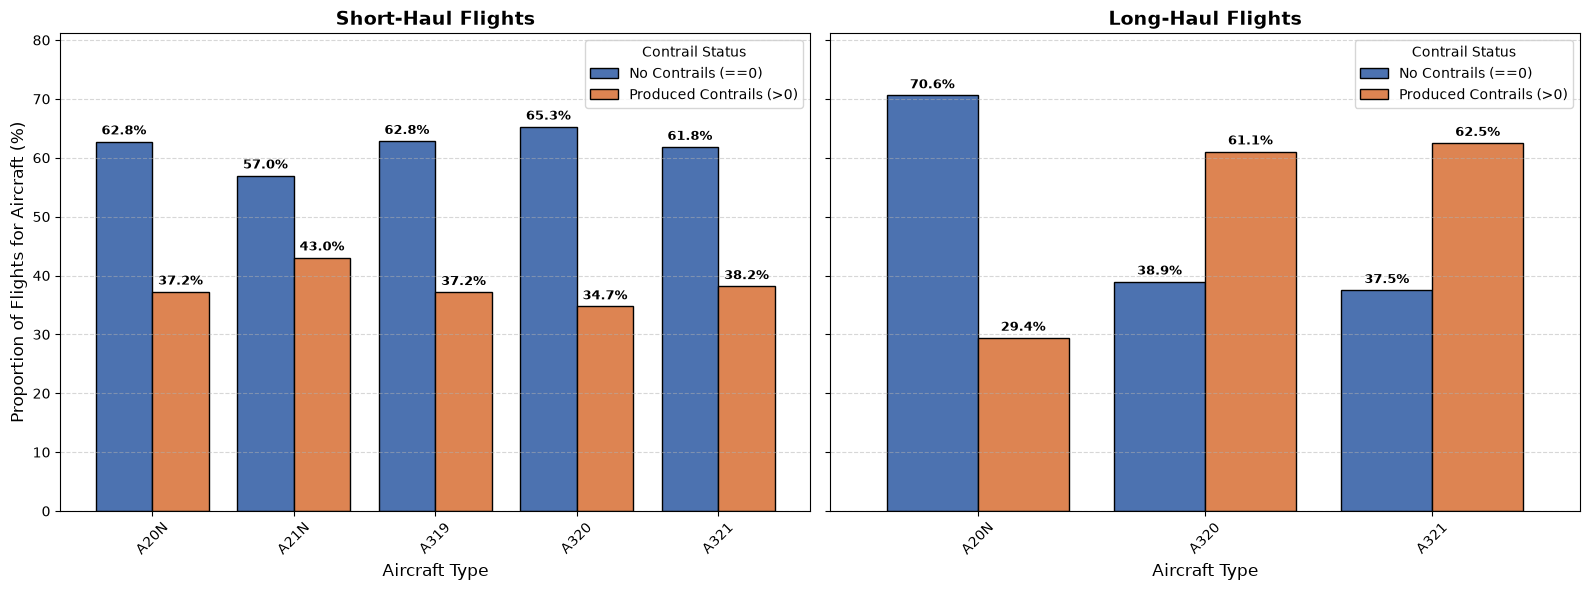

In [93]:
data['Contrail_Status'] = np.where(
    data['Contrails (kgCO2e)'] > 0, 
    'Produced Contrails (>0)', 
    'No Contrails (==0)'
)

# 3. Create side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

haul_configs = [
    {'val': 0, 'title': 'Short-Haul Flights', 'ax': axes[0]},
    {'val': 1, 'title': 'Long-Haul Flights', 'ax': axes[1]}
]

# Track max percentage for consistent y-limits
max_pct = 0

for cfg in haul_configs:
    ax = cfg['ax']
    # Filter for the specific haul category (handles 1/0 or True/False)
    subset = data[is_long_haul == bool(cfg['val'])].copy()
    
    if subset.empty:
        ax.set_title(f"{cfg['title']} (No Data)", fontsize=14, weight='bold')
        continue

    # normalize='index' calculates % per aircraft type (row sums to 100%)
    pcts = pd.crosstab(
        subset['Aircraft'], 
        subset['Contrail_Status'], 
        normalize='index'
    ) * 100

    # Ensure consistent column ordering even if a category has 0 occurrences
    for col in ['No Contrails (==0)', 'Produced Contrails (>0)']:
        if col not in pcts.columns:
            pcts[col] = 0.0
    pcts = pcts[['No Contrails (==0)', 'Produced Contrails (>0)']]

    # Plot grouped bars
    pcts.plot(
        kind='bar',
        ax=ax,
        width=0.8,
        color=['#4C72B0', '#DD8452'],
        edgecolor='black'
    )

    # Annotate bars with percentage labels
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9, weight='bold')

    max_pct = max(max_pct, pcts.to_numpy().max())

    ax.set_title(cfg['title'], fontsize=14, weight='bold')
    ax.set_xlabel('Aircraft Type', fontsize=12)
    ax.set_ylabel('Proportion of Flights for Aircraft (%)', fontsize=12)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend(title='Contrail Status')

# Apply unified y-axis limit with headroom for annotations
for ax in axes:
    ax.set_ylim(0, max_pct * 1.15)

plt.tight_layout()
plt.show()

In [96]:
# 1. Load the official ICAO airport database (built-in dictionary of ~28,000 airports)
airports = airportsdata.load('ICAO')

# Replace with your actual origin airport column name if different
origin_col = 'Origin Airport' 

# 2. Map origin ICAO codes to their official IANA time zone (e.g., 'Europe/London', 'Europe/Madrid')
data['Timezone'] = data[origin_col].map(
    lambda code: airports[code]['tz'] if code in airports else 'UTC'
)

# 3. Ensure the take-off timestamp is a UTC-aware datetime
# (If your column is currently just HH:MM:SS strings, combine it with your 'Date' column first)
if 'Date' in data.columns and not pd.api.types.is_datetime64_any_dtype(data['Take-off Time (UTC)']):
    full_timestamp = pd.to_datetime(data['Date'].astype(str) + ' ' + data['Take-off Time (UTC)'].astype(str))
else:
    full_timestamp = pd.to_datetime(data['Take-off Time (UTC)'])

# Localize to UTC
full_timestamp = full_timestamp.dt.tz_localize('UTC') if full_timestamp.dt.tz is None else full_timestamp

# 4. Convert UTC to the airport's local hour
# Grouping by timezone makes the conversion fast even for millions of rows
def get_local_hour(df, ts_series):
    local_hours = pd.Series(index=df.index, dtype='int64')
    for tz_name, group in df.groupby('Timezone'):
        local_hours.loc[group.index] = ts_series.loc[group.index].dt.tz_convert(tz_name).dt.hour
    return local_hours

data['Local_Hour'] = get_local_hour(data, full_timestamp)

# 5. Create the boolean indicator column
# Cold hours: Early morning (midnight to 06:59) OR Late evening (20:00 to 23:59)
data['Is_Cold_Hours'] = (data['Local_Hour'] < 7) | (data['Local_Hour'] >= 20)

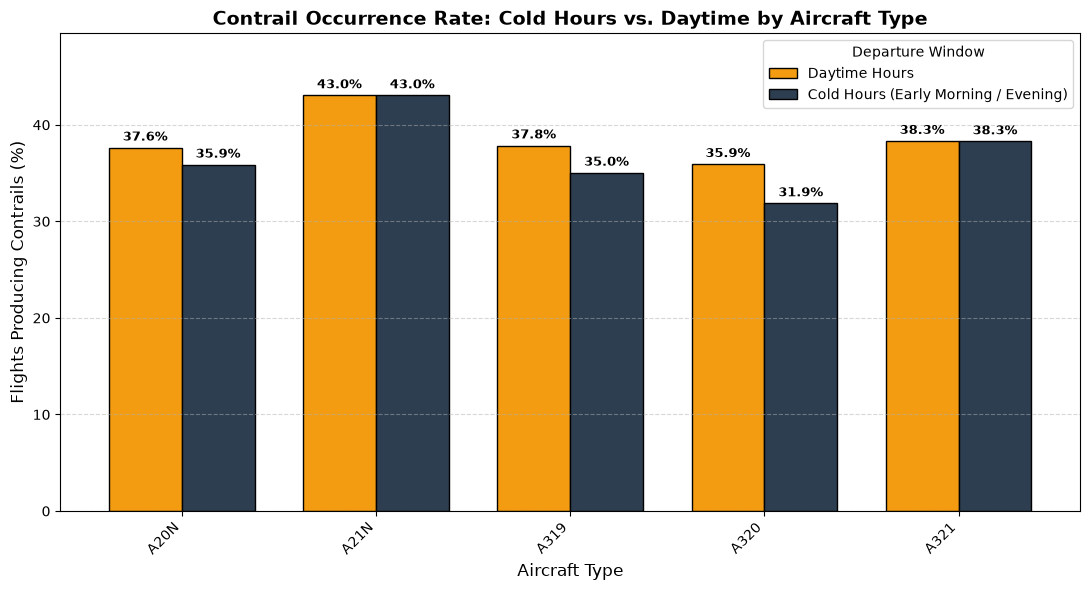

In [97]:

# 1. Define boolean flag for contrail production
data['Has_Contrails'] = data['Contrails (kgCO2e)'] > 0

# 2. Compute contrail percentage by Aircraft and Time of Day
contrail_rates = (
    data.groupby(['Aircraft', 'Is_Cold_Hours'])['Has_Contrails']
    .mean()
    .unstack()
    * 100
)

# Rename columns for clarity in the legend
contrail_rates = contrail_rates.rename(
    columns={
        False: 'Daytime Hours',
        True: 'Cold Hours (Early Morning / Evening)'
    }
)

# 3. Plot side-by-side bars
fig, ax = plt.subplots(figsize=(11, 6))

contrail_rates.plot(
    kind='bar',
    ax=ax,
    width=0.75,
    color=['#F39C12', '#2C3E50'],  # Warm tone for daytime, dark tone for cold hours
    edgecolor='black'
)

# 4. Add percentage labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9, weight='bold')

# Scale y-axis up to 100% (or max value + headroom)
max_val = contrail_rates.to_numpy().max()
ax.set_ylim(0, min(100, max_val * 1.15))

# 5. Styling
plt.title('Contrail Occurrence Rate: Cold Hours vs. Daytime by Aircraft Type', fontsize=14, weight='bold')
plt.xlabel('Aircraft Type', fontsize=12)
plt.ylabel('Flights Producing Contrails (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Departure Window', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

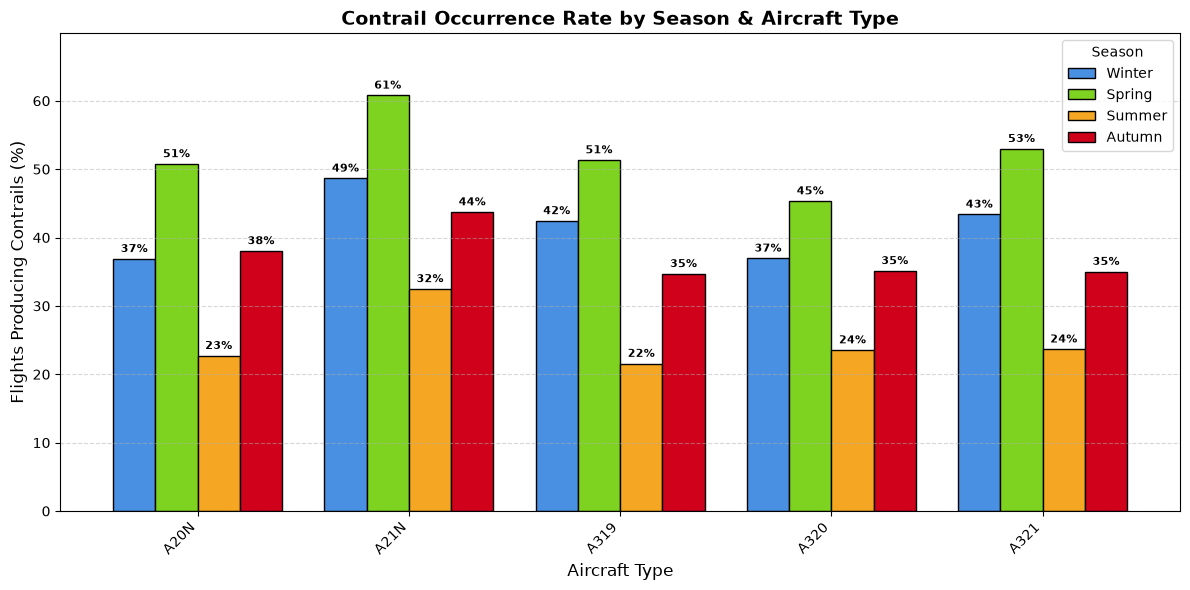

In [98]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Ensure 'Date' is datetime
data['Date'] = pd.to_datetime(data['Date'])

# 2. Map months to meteorological seasons (Northern Hemisphere standard)
season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring',  4: 'Spring', 5: 'Spring',
    6: 'Summer',  7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}
data['Season'] = data['Date'].dt.month.map(season_map)

# 3. Ensure Contrail flag exists
data['Has_Contrails'] = data['Contrails (kgCO2e)'] > 0

# 4. Compute contrail occurrence rate (%) per Aircraft and Season
season_rates = (
    data.groupby(['Aircraft', 'Season'])['Has_Contrails']
    .mean()
    .unstack()
    * 100
)

# Enforce chronological seasonal order
ordered_seasons = ['Winter', 'Spring', 'Summer', 'Autumn']
season_rates = season_rates[[s for s in ordered_seasons if s in season_rates.columns]]

# 5. Plot grouped bar chart
fig, ax = plt.subplots(figsize=(12, 6))

season_rates.plot(
    kind='bar',
    ax=ax,
    width=0.8,
    color=['#4A90E2', '#7ED321', '#F5A623', '#D0021B'],  # Seasonal palette (Cool -> Warm)
    edgecolor='black'
)

# 6. Add percentage labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, fontsize=8, weight='bold')

# Scale y-axis headroom
max_val = season_rates.to_numpy().max() if season_rates.size > 0 else 0
ax.set_ylim(0, min(100, max_val * 1.15))

# 7. Styling
plt.title('Contrail Occurrence Rate by Season & Aircraft Type', fontsize=14, weight='bold')
plt.xlabel('Aircraft Type', fontsize=12)
plt.ylabel('Flights Producing Contrails (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Season', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

In [101]:
# 1. Load ICAO airport database
airports = airportsdata.load('ICAO')

# 2. Extract Origin and Destination Latitudes
# (Replace 'Origin' and 'Destination' with your exact column names)
data['Origin_Lat'] = data['Origin Airport'].map(lambda code: airports[code]['lat'] if code in airports else np.nan)
data['Dest_Lat'] = data['Destination Airport'].map(lambda code: airports[code]['lat'] if code in airports else np.nan)

# Mean latitude of the flight route
data['Route_Lat'] = data[['Origin_Lat', 'Dest_Lat']].mean(axis=1)

# 3. Ensure 'Date' is datetime and get the month
data['Date'] = pd.to_datetime(data['Date'])
month = data['Date'].dt.month

# 4. Map Season per Hemisphere
# Northern Hemisphere (lat >= 0)
north_seasons = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring',  4: 'Spring', 5: 'Spring',
    6: 'Summer',  7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}

# Southern Hemisphere (lat < 0) — completely flipped
south_seasons = {
    12: 'Summer', 1: 'Summer', 2: 'Summer',
    3: 'Autumn',  4: 'Autumn', 5: 'Autumn',
    6: 'Winter',  7: 'Winter', 8: 'Winter',
    9: 'Spring', 10: 'Spring', 11: 'Spring'
}

is_south = data['Route_Lat'] < 0

data['Season'] = np.where(
    is_south,
    month.map(south_seasons),
    month.map(north_seasons)
)

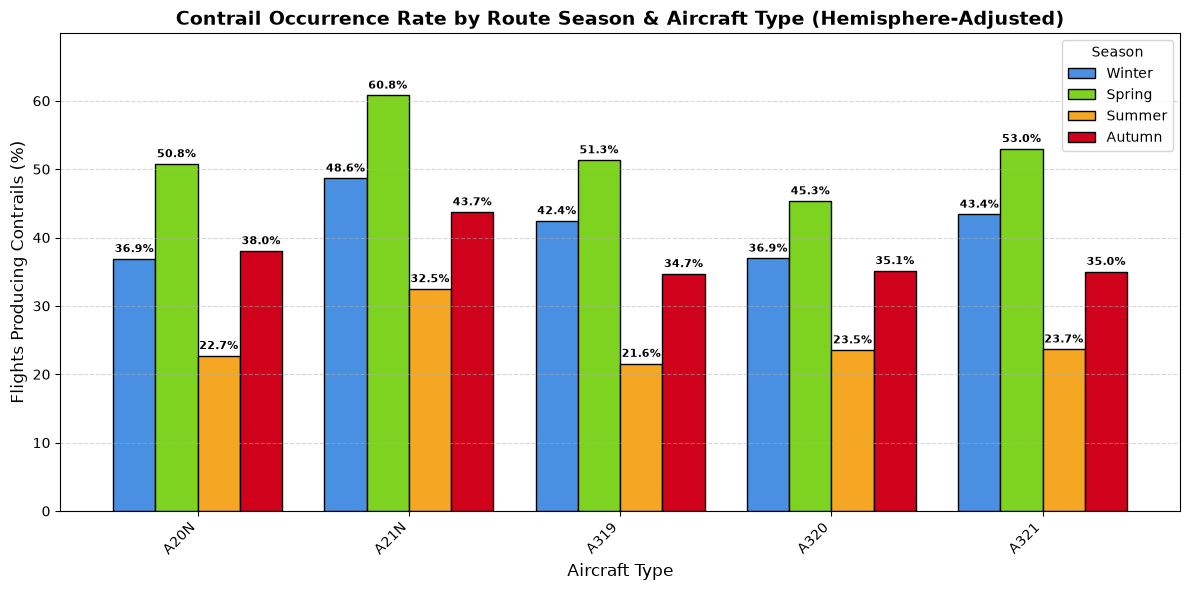

In [104]:
import matplotlib.pyplot as plt

# 1. Ensure Contrail flag exists
data['Has_Contrails'] = data['Contrails (kgCO2e)'] > 0

# 2. Compute contrail percentage by Aircraft and Season
season_rates = (
    data.groupby(['Aircraft', 'Season'])['Has_Contrails']
    .mean()
    .unstack()
    * 100
)

# Enforce clean chronological seasonal order
ordered_seasons = ['Winter', 'Spring', 'Summer', 'Autumn']
season_rates = season_rates[[s for s in ordered_seasons if s in season_rates.columns]]

# 3. Plot grouped bars
fig, ax = plt.subplots(figsize=(12, 6))

season_rates.plot(
    kind='bar',
    ax=ax,
    width=0.8,
    color=['#4A90E2', '#7ED321', '#F5A623', '#D0021B'],  # Blue (Winter), Green (Spring), Orange (Summer), Red (Autumn)
    edgecolor='black'
)

# 4. Add percentage labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=8, weight='bold')

# Scale y-axis headroom
max_val = season_rates.to_numpy().max() if season_rates.size > 0 else 0
ax.set_ylim(0, min(100, max_val * 1.15))

# 5. Styling
plt.title('Contrail Occurrence Rate by Route Season & Aircraft Type (Hemisphere-Adjusted)', fontsize=14, weight='bold')
plt.xlabel('Aircraft Type', fontsize=12)
plt.ylabel('Flights Producing Contrails (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Season', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

## Can we combine hypotheses somehow?

Specific engine type on long-haul routes or specific seasons?
